# The counterbalancing capacity: haircuts, monetisation capacity and held-to-maturity losses

- **Level:** 2, The method in practice
- **Prerequisites:** notebooks 01 and 02 of this topic
- **Reading time:** about 40 minutes

## Objectives

By the end of this notebook you can:

- compute the liquidity value of an asset class (market value, less the encumbered part, less a haircut) and say which rule gave each haircut;
- turn the liquidity values into a counterbalancing capacity (CBC) that grows day by day with a monetisation schedule;
- measure how the unrealised loss of a held-to-maturity (HTM) book removes CBC and shortens the survival period;
- read the product's tests on the haircut rules, on the HTM effect and on the revaluation of the HTM book, with the engine version that baked them.

## Setup

Install the pinned environment once, in a virtual environment, with the familiar command:

```bash
pip install -r notebooks/requirements.txt
```

or only the packages this notebook uses, with the same exact pins:

```bash
pip install riskvalidation==0.9.0 numpy==2.4.6 scipy==1.18.1 matplotlib==3.11.2
```

`scripts/setup.sh --notebooks` (`scripts/setup.ps1 -Notebooks` on Windows) builds `.venv-notebooks` for you. The next cell imports the packages and prints their versions.

In [1]:
# Import the tools and print the versions they run with, to compare them with notebooks/requirements.txt
import importlib.metadata as md
import json
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import riskvalidation as rv

for name in ("riskvalidation", "numpy", "scipy", "matplotlib"):
    print(name, md.version(name))

riskvalidation 0.8.1
numpy 2.4.6
scipy 1.18.1
matplotlib 3.11.2


## Data

Two committed documents of case C16 (real FDIC call-report aggregates of the bank that failed on 2023-03-10 up to 2022-12-31, synthetic behaviour and deposits, licence class `mirror-allowed`):

- `data/derived/C16/list-adverse.json`: the CBC classes at the carrying value of the securities (the amortised-cost basis), the conventions of the haircuts and of the monetisation schedule, and the survival period.
- `data/derived/C16/htm-losses.json`: the same ladder with the securities book at fair value, the effect of the loss on the CBC and the committed tests.

The central bank haircuts are one minus the margins of the Federal Reserve discount window in force on 2023-03-10 (Federal Reserve discount window, 2022-2023), taken by class from the document. Amounts are in USD thousands.

In [2]:
# Load the two committed documents (the notebook sits three folders below the repository root)
ROOT = Path("../../..").resolve()
adverse = json.loads((ROOT / "data" / "derived" / "C16" / "list-adverse.json").read_text(encoding="utf-8"))
htm_doc = json.loads((ROOT / "data" / "derived" / "C16" / "htm-losses.json").read_text(encoding="utf-8"))
out, htm_out = adverse["outputs"], htm_doc["outputs"]

for name, doc in (("list-adverse", adverse), ("htm-losses", htm_doc)):
    print(name, "| baked by riskvalidation", doc["provenance"]["riskvalidation_version"], "| installed", rv.__version__)
print("valuation date:", out["valuation_date"], "| haircut framework in force from", out["cbc"]["haircut_framework"]["effective_from"], "to", out["cbc"]["haircut_framework"]["effective_to"])

list-adverse | baked by riskvalidation 0.8.1 | installed 0.8.1
htm-losses | baked by riskvalidation 0.8.1 | installed 0.8.1
valuation date: 2022-12-31 | haircut framework in force from 2022-03-14 to 2023-03-12


## Method

### Step 1: the liquidity value of an asset

The liquidity value of an asset class is its market value less a haircut, and only the unencumbered part counts (ECB, 2019, methodological note, paragraphs 63 and 74). With market value $M$, encumbered part $E$ and haircut $h$:

$$\mathrm{LV} = (M - E)\,(1 - h)$$

The call report gives the securities by type at their carrying value and the pledged amount (`SCPLEDGE`); the document spreads the pledged amount pro rata across the types, a stated assumption. The next cell takes the six classes of the document, calls `liquidity_value` and compares each result with the committed one.

In [3]:
# The liquidity value of each class from its market value, encumbered part and haircut
from riskvalidation.liquidity.cbc import liquidity_value

classes = out["cbc"]["classes"]
print(f"{'class':18s}{'value used':>14s}{'encumbered':>14s}{'haircut':>10s}{'liquidity value':>20s}{'committed':>14s}   (USD billions)")
for c in classes:
    lv = liquidity_value(c["value_used"], c["haircut"]["value"], c["encumbered"])
    print(f"{c['class_id']:18s}{c['value_used'] / 1e6:14.3f}{c['encumbered'] / 1e6:14.3f}{c['haircut']['value']:10.2f}{lv / 1e6:20.3f}{c['liquidity_value'] / 1e6:14.3f}")
total = sum(liquidity_value(c["value_used"], c["haircut"]["value"], c["encumbered"]) for c in classes)
print("total liquidity value (USD billions):", round(total / 1e6, 4), "| committed:", round(out["cbc"]["total_liquidity_value"] / 1e6, 4))
print("pledged share of the securities:", round(out["cbc"]["pledged"]["share_of_securities"], 4))

class                 value used    encumbered   haircut     liquidity value     committed   (USD billions)
cash-and-balances         12.511         0.000      0.00              12.511        12.511
treasury                  16.043         7.571      0.02               8.302         8.302
mortgage-backed           91.460        43.164      0.04              46.364        46.364
other-agency               0.587         0.277      0.03               0.301         0.301
municipal                  7.417         3.500      0.05               3.721         3.721
other-debt                 1.796         0.848      0.50               0.474         0.474
total liquidity value (USD billions): 71.6726 | committed: 71.6726
pledged share of the securities: 0.4719


### Step 2: which rule gave the haircut

The note fixes an order for the haircut of an asset (paragraph 74): cash at nominal value (haircut 0); a central-bank-eligible asset takes the central bank's haircut; if that cannot be determined, the LCR haircut when the asset is high-quality liquid (HQLA) and 50% otherwise; a marketable asset that is not eligible takes the table of equities by rating (20%, 35%, 50%) or 30% if it is HQLA and 50% if not. `haircut_rule` returns the haircut and the label of the rule that gave it. The next cell applies it to the classes of the document, with the central bank haircut of each class (one minus the Federal Reserve margin) when the framework gives one.

In [4]:
# The haircut rule of each class: the central bank haircut when the Federal Reserve gives a margin, the fallback when it does not
from riskvalidation.liquidity.cbc import haircut_rule

mapping = {row["class_id"]: row for row in out["conventions"]["cbc_securities_mapping"]["rows"]}
print(f"{'class':18s}{'margin':>10s}{'maturity bucket':>20s}{'haircut':>10s}  rule given by the engine")
for c in classes:
    row = mapping[c["class_id"]]
    if c["class_id"] == "cash-and-balances":
        haircut, rule = haircut_rule("cash")
    else:
        haircut, rule = haircut_rule("non-equity", central_bank_eligible=True, central_bank_haircut=None if row["margin"] is None else 1.0 - row["margin"])
    margin = "-" if row["margin"] is None else f"{row['margin']:.2f}"
    bucket = "-" if row["duration_bucket"] == "none" else row["duration_bucket"]
    same = abs(haircut - c["haircut"]["value"]) < 1e-12 and rule == c["haircut"]["rule"]
    print(f"{c['class_id']:18s}{margin:>10s}{bucket:>20s}{haircut:10.2f}  {rule} | same as the document: {same}")

class                 margin     maturity bucket   haircut  rule given by the engine
cash-and-balances          -                   -      0.00  nominal-value | same as the document: True
treasury                0.98                >3-5      0.02  central-bank-framework | same as the document: True
mortgage-backed         0.96               >5-10      0.04  central-bank-framework | same as the document: True
other-agency            0.97                >3-5      0.03  central-bank-framework | same as the document: True
municipal               0.95               >5-10      0.05  central-bank-framework | same as the document: True
other-debt                 -                   -      0.50  fifty-percent-fallback | same as the document: True


The product also commits a test that runs the whole order of the note on nine constructed cases (the three equity bands, the HQLA and the fallback cases, the central bank cases, cash). The next cell calls it and prints the cases beside the committed row and the engine version that baked it.

In [5]:
# The haircut-rule test on nine constructed cases, and its committed row
from riskvalidation.validation.liquidity import cbc_haircut_rules

rules = cbc_haircut_rules()
committed_rule = next(row for row in adverse["tests"] if row["test_id"] == "liq.cbc_haircut_rules")

for case in rules.extras["cases"]:
    print(f"{case['kind']:12s} expected {str(case['expected']):38s} got {case['got']}")
print("cases:", rules.n, "| largest difference:", rules.statistic, "| light:", rules.light.value)
print("committed row:", committed_rule["light"], committed_rule["n"], "| baked by", adverse["provenance"]["riskvalidation_version"])

equity       expected [0.2, 'ecb-equity-table']              got [0.2, 'ecb-equity-table']
equity       expected [0.35, 'ecb-equity-table']             got [0.35, 'ecb-equity-table']
equity       expected [0.5, 'ecb-equity-table']              got [0.5, 'ecb-equity-table']
non-equity   expected [0.3, 'ecb-non-equity-hqla']           got [0.3, 'ecb-non-equity-hqla']
non-equity   expected [0.5, 'fifty-percent-fallback']        got [0.5, 'fifty-percent-fallback']
non-equity   expected [0.04, 'central-bank-framework']       got [0.04, 'central-bank-framework']
non-equity   expected [0.15, 'lcr-haircut-hqla']             got [0.15, 'lcr-haircut-hqla']
non-equity   expected [0.5, 'fifty-percent-fallback']        got [0.5, 'fifty-percent-fallback']
cash         expected [0.0, 'nominal-value']                 got [0.0, 'nominal-value']
cases: 9 | largest difference: 0.0 | light: green
committed row: green 9 | baked by 0.8.1


### Step 3: from liquidity value to a CBC that grows by day

Assets are not cash on day 1. A monetisation schedule gives the cumulative share of the liquidity value that can be turned into cash by each day, so the CBC of day $d$ is:

$$\mathrm{CBC}(d) = \sum_{c} \mathrm{LV}_c \; \sigma(d)$$

where $\sigma(d)$ is the share of the last point of the schedule with day $\le d$ (zero before the first point). The dossier names the capacity per day but gives no value, so the schedule of the document (50% on day 1, 80% on day 2, 100% on day 3) is a stated convention, with an immediate and a slow bound. `cbc_stack` returns the CBC by class; the next cell compares its sum with the committed daily CBC and shows the three schedules at days 1, 5 and 10.

In [6]:
# The CBC stack by class under the schedule of the document, and the immediate and slow bounds
from riskvalidation.liquidity.cbc import cbc_stack, monetisation_capacity

schedule = out["conventions"]["monetisation_schedule"]
points = [(p["day"], p["cumulative_share"]) for p in schedule["points"]]
stack = cbc_stack({c["class_id"]: (c["value_used"], c["encumbered"], c["haircut"]["value"]) for c in classes}, points, 125)
cbc_total = sum(stack.values())

print("schedule (day, cumulative share):", points)
print("same daily CBC as the document:", bool(np.allclose(cbc_total, out["path"]["ladder"]["cbc_total"])))
print("CBC of day 1 by class (USD billions):", {k: round(float(v[0]) / 1e6, 3) for k, v in stack.items()})
names = {"immediate": "immediate", "slow": "slow"}
for band in schedule["sensitivity_band"]:
    bound = monetisation_capacity(total, [(p["day"], p["cumulative_share"]) for p in band["points"]], 125)
    print(f"{names[band['id']]:10s} CBC at days 1, 5 and 10 (USD billions):", [round(float(bound[d - 1]) / 1e6, 2) for d in (1, 5, 10)])
document_bound = monetisation_capacity(total, points, 125)
print(f"{'document':10s} CBC at days 1, 5 and 10 (USD billions):", [round(float(document_bound[d - 1]) / 1e6, 2) for d in (1, 5, 10)])

schedule (day, cumulative share): [(1, 0.5), (2, 0.8), (3, 1.0)]
same daily CBC as the document: True
CBC of day 1 by class (USD billions): {'cash-and-balances': 6.255, 'treasury': 4.151, 'mortgage-backed': 23.182, 'other-agency': 0.15, 'municipal': 1.86, 'other-debt': 0.237}
immediate  CBC at days 1, 5 and 10 (USD billions): [71.67, 71.67, 71.67]
slow       CBC at days 1, 5 and 10 (USD billions): [17.92, 43.0, 71.67]
document   CBC at days 1, 5 and 10 (USD billions): [35.84, 71.67, 71.67]


### Step 4: the unrealised loss of a held-to-maturity book

A held-to-maturity book is carried at amortised cost, so the call report hides its loss from the liquidity picture; but a bank that has to sell or pledge those securities in a stress receives their fair value, not their carrying value. Unrealised losses therefore reduce the effective CBC and can trigger runs (Jiang et al., 2024; ECB, 2019). For a class with carrying value $K$, fair value $V$, encumbered part $E$ and haircut $h$:

$$\Delta = V - K, \qquad \mathrm{CBC}_{\text{with}} = (V - E)(1 - h), \qquad \mathrm{removed} = (K - E)(1 - h) - (V - E)(1 - h)$$

The call report gives the reported fair value of the held-to-maturity book (`SCHF`) and of the available-for-sale book; it gives no loss by type. The document applies the reported loss to the whole securities book pro rata by type, a stated assumption, never a reported loss by type. The encumbered amount is the same on both bases. The next cell runs `cbc_with_htm_loss` class by class.

In [7]:
# The CBC with and without the loss, class by class, from the engine; cash has no loss
from riskvalidation.liquidity.cbc import cbc_with_htm_loss

htm = htm_out["htm"]
carrying = {c["class_id"]: c for c in classes}
cash = carrying["cash-and-balances"]["liquidity_value"]
without, with_loss = cash, cash
print(f"{'class':18s}{'unrealised loss':>22s}{'CBC without':>14s}{'CBC with':>14s}{'removed':>12s}   (USD billions)")
for c in htm_out["cbc"]["classes"]:
    if c["class_id"] == "cash-and-balances":
        continue
    base = carrying[c["class_id"]]
    result = cbc_with_htm_loss(base["carrying_value"], c["fair_value"], c["encumbered"], c["haircut"]["value"])
    without += result.cbc_without_loss
    with_loss += result.cbc_with_loss
    print(f"{c['class_id']:18s}{result.unrealised_loss / 1e6:22.3f}{result.cbc_without_loss / 1e6:14.3f}{result.cbc_with_loss / 1e6:14.3f}{result.cbc_removed / 1e6:12.3f}")
print("total CBC without and with the loss (USD billions):", round(without / 1e6, 4), round(with_loss / 1e6, 4), "| removed:", round((without - with_loss) / 1e6, 4))
print("same as the document:", bool(np.isclose(without, htm["cbc_without_loss"]) and np.isclose(with_loss, htm["cbc_with_loss"]) and np.isclose(without - with_loss, htm["cbc_removed"])))

class                    unrealised loss   CBC without      CBC with     removed   (USD billions)
treasury                          -2.073         8.302         6.270       2.032
mortgage-backed                  -11.819        46.364        35.017      11.347
other-agency                      -0.076         0.301         0.227       0.074
municipal                         -0.958         3.721         2.810       0.911
other-debt                        -0.232         0.474         0.358       0.116
total CBC without and with the loss (USD billions): 71.6726 57.1941 | removed: 14.4785
same as the document: True


### Step 5: the effect on the survival period

The test `liq.htm_loss_effect` takes the CBC and the survival period without and with the loss and checks the direction of the effect: the loss should not raise the CBC and should not lengthen the survival period. Its statistic is the CBC removed and its metric the share of the CBC removed. A green light says the effect has the expected sign, not that the loss is small. The survival periods are those of the two documents (LiST Adverse on the carrying value and on the fair value). The next cell calls the test and sets it beside the committed row.

In [8]:
# The HTM loss effect test: CBC and survival period without and with the loss
from riskvalidation.validation.liquidity import htm_loss_effect

survival_without = out["path"]["survival"]["day"]
survival_with = htm_out["path"]["survival"]["day"]
effect = htm_loss_effect(without, with_loss, survival_without, survival_with)
committed_effect = next(row for row in htm_doc["tests"] if row["test_id"] == "liq.htm_loss_effect")

print("survival period without and with the loss (days):", survival_without, survival_with)
print("CBC removed (USD billions):", round(effect.statistic / 1e6, 4), "| share of the CBC:", round(effect.metric, 6), "| light:", effect.light.value)
print("committed row:", round(committed_effect["statistic"] / 1e6, 4), round(committed_effect["metric"], 6), committed_effect["light"], "| baked by", htm_doc["provenance"]["riskvalidation_version"])

survival period without and with the loss (days): 62 44
CBC removed (USD billions): 14.4785 | share of the CBC: 0.202009 | light: green
committed row: 14.4785 0.202009 green | baked by 0.8.1


The loss is also a dial. `htm_loss_grid` scales the reported loss by a multiple (0 removes it, 1 is the reported loss) and the document runs the ladder at each multiple. The next cell recomputes the losses of the grid from the reported one and prints them with the committed CBC and survival period of each multiple.

In [9]:
# The HTM loss grid: the engine's losses against the committed ones, with the committed CBC and survival period
from riskvalidation.liquidity.scenarios import htm_loss_grid

grid = out["sensitivities"]["htm_loss"]
losses = htm_loss_grid(htm["reported"]["htm_unrealised"], [row["multiple"] for row in grid])
print(f"{'multiple':>10s}{'loss (USD billions)':>34s}{'CBC':>10s}{'survival day':>24s}")
for row, loss in zip(grid, losses):
    print(f"{row['multiple']:10.1f}{loss / 1e6:34.3f}{row['cbc'] / 1e6:10.2f}{row['survival']['day']:24d}")
print("same losses as the document:", bool(np.allclose(losses, [row["unrealised_loss"] for row in grid])))

  multiple               loss (USD billions)       CBC            survival day
       0.0                            -0.000     71.67                      62
       0.5                            -7.580     64.43                      53
       1.0                           -15.159     57.19                      44
       1.5                           -22.738     49.95                      36
       2.0                           -30.318     42.72                      28
same losses as the document: True


### Step 6: does the engine reproduce the reported fair value?

The product does not take the reported fair value on trust. The test `liq.htm_revaluation_vs_reported` revalues the HTM book from its maturity profile under the Treasury par curve (a par bond per maturity band, through the engine's `irrbb` curves) and compares it with the reported fair value $V_r$, as a share of the reported unrealised loss:

$$\text{statistic} = \frac{|V_{\text{model}} - V_r|}{|V_r - K|}$$

The light is an internal gate of the product (green up to 0.05, amber up to 0.15, red above), not a regulatory threshold. The revaluation is committed in the document; the next cell calls the test with those inputs, reads the committed row, and prints the Bank Term Funding Program counterfactual that the document also carries (par valuation announced on 2023-03-12, after the run).

In [10]:
# The revaluation test with the committed revaluation of the document, and the par counterfactual
from riskvalidation.validation.liquidity import htm_revaluation_vs_reported

revaluation = htm["revaluation"]
check = htm_revaluation_vs_reported(revaluation["model_fair_value"], htm["reported"]["htm_fair_value"], htm["reported"]["htm_amortised_cost"])
committed_check = next(row for row in htm_doc["tests"] if row["test_id"] == "liq.htm_revaluation_vs_reported")

print("reported fair value and revalued (USD billions):", round(htm["reported"]["htm_fair_value"] / 1e6, 3), round(revaluation["model_fair_value"] / 1e6, 3))
print("statistic:", round(check.statistic, 6), "| difference (USD billions):", round(check.metric / 1e6, 3), "| light:", check.light.value)
print("committed row:", round(committed_check["statistic"], 6), committed_check["light"], "| same statistic:", bool(np.isclose(check.statistic, committed_check["statistic"])))
par = htm["btfp_par"]
print("counterfactual at par: CBC and uplift (USD billions):", round(par["cbc_at_par"] / 1e6, 3), round(par["uplift"] / 1e6, 3), "|", par["announced"])

reported fair value and revalued (USD billions): 76.168 71.9
statistic: 0.281548 | difference (USD billions): -4.268 | light: red
committed row: 0.281548 red | same statistic: True
counterfactual at par: CBC and uplift (USD billions): 73.783 2.111 | 2023-03-12


The last cell draws the two lessons. On the left, the CBC of each class on the carrying basis and with the loss: the mortgage-backed securities carry most of the CBC and most of the loss. On the right, the survival period against the multiple of the reported loss: each half of the reported loss costs the bank days.

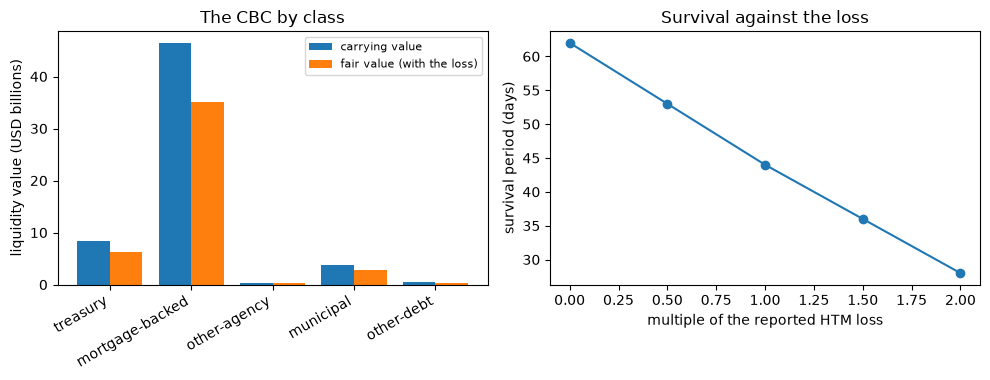

In [11]:
# Draw the CBC by class with and without the loss, and the survival period against the loss multiple
fig, (left, right) = plt.subplots(1, 2, figsize=(10, 3.9))

names = [c["class_id"] for c in classes if c["class_id"] != "cash-and-balances"]
position = np.arange(len(names))
carrying_values = [carrying[k]["liquidity_value"] / 1e6 for k in names]
fair_values = [next(c for c in htm_out["cbc"]["classes"] if c["class_id"] == k)["liquidity_value"] / 1e6 for k in names]
left.bar(position - 0.2, carrying_values, width=0.4, label="carrying value")
left.bar(position + 0.2, fair_values, width=0.4, label="fair value (with the loss)")
left.set_xticks(position)
left.set_xticklabels(names, rotation=30, ha="right")
left.set_ylabel("liquidity value (USD billions)")
left.set_title("The CBC by class")
left.legend(fontsize=8)

right.plot([row["multiple"] for row in grid], [row["survival"]["day"] for row in grid], marker="o")
right.set_xlabel("multiple of the reported HTM loss")
right.set_ylabel("survival period (days)")
right.set_title("Survival against the loss")
fig.tight_layout()
plt.show()

## Results

- **Liquidity values.** The six classes give a total liquidity value of 71.6726 billion USD and the engine reproduces every class. The mortgage-backed securities hold 46.364 billion of it, after 43.164 billion of their 91.460 billion are encumbered: the pledged securities are 0.4719 of the securities book and leave the CBC.
- **Haircut rules.** Four classes take the Federal Reserve margin (haircuts from 0.02 to 0.05), cash is at nominal value, and the class of other debt, which has no margin, falls back to 50%. The rule label of every class equals the document's. The haircut test on the nine constructed cases is green with a largest difference of 0.0, as in the committed row.
- **The CBC by day.** Under the schedule of the document the CBC is 35.84 billion on day 1 and the full 71.67 billion from day 5; under the immediate bound it is 71.67 from day 1, and under the slow bound it is 17.92, 43.00 and 71.67 on days 1, 5 and 10. The schedule moves the first days, not the total, and it is a convention: the dossier names the capacity per day and gives no value.
- **The HTM loss.** Applying the reported held-to-maturity loss (15.159 billion) pro rata removes 14.4785 billion of CBC, 0.202009 of it (from 71.6726 to 57.1941), 11.347 billion of that in mortgage-backed securities. The survival period falls from 62 to 44 days, and each half step of the loss costs 8 or 9 days. The test is green because the effect has the expected sign; the engine and the committed row agree.
- **The revaluation.** The engine's revaluation of the HTM book, 71.900 billion, is 4.268 billion below the reported fair value of 76.168 billion: 0.281548 of the reported unrealised loss, red under the gates of 0.05 and 0.15, the same as the committed row. The counterfactual at par (the valuation announced on 2023-03-12, after the run) would have lifted the CBC by 2.111 billion to 73.783 billion. The red light says the model and the reported figure disagree, so the loss used above is itself uncertain; the model values a par bond per maturity band, a simplification, so it is not a finding on the bank's accounts.

What this notebook does not show: the outflow side of the NLP (notebooks 02 and 04) or the LCR view of the same assets (notebook 05). The HTM loss is spread pro rata by type because the call report gives none by type; the survival periods are properties of synthetic behaviour.

## Summary

- The liquidity value of an asset is $(M-E)(1-h)$; the rule that gave the haircut is part of the result, and the engine returns its label.
- The CBC is not the sum of the liquidity values on day 1: it follows a monetisation schedule, a stated convention with an immediate and a slow bound.
- The unrealised loss of a held-to-maturity book removes CBC and survival days, and the effect grows with the loss.
- The engine's own revaluation of the HTM book does not reproduce the reported fair value within the product's gate: the reported figure is an input to be tested, not a given.

**What to try next.** Change the multiple of the grid to 3 and look at the survival period; then continue with notebook 04, where the outflow side is composed into scenarios.

## References

- ECB Banking Supervision (2019), Sensitivity analysis of liquidity risk, stress test 2019, methodological note (2019-02-06), paragraphs 63, 73 and 74 and Table 2.1. https://www.bankingsupervision.europa.eu/ecb/pub/pdf/ssm.ECB_sensitivity_analysis_of_liquidity_risk-stress_test_2019-methodological_note_20190206~6771e88926.en.pdf
- Federal Reserve discount window, securities margins in force from 2022-03-14 to 2023-03-12. https://www.frbdiscountwindow.org/generalpages/historical_margins/2022/03142022_03122023_securities_table
- Jiang, E. X., Matvos, G., Piskorski, T. and Seru, A. (2024), Monetary tightening and U.S. bank fragility in 2023: mark-to-market losses and uninsured depositor runs?, Journal of Financial Economics 159. https://doi.org/10.1016/j.jfineco.2024.103899